# Zoom severity: check the effect before calling it a bug

## tl;dr

Extreme zoom raises the paired ensemble known-angle OOF log loss by **0.004056** versus mild zoom. The two seed deltas are **+0.006397** and **+0.003993**; **8/10** paired seed/fold deltas worsen and **2/10** improve.

Extreme zoom has higher loss on the primary ensemble metric in this controlled setting. That does not establish a universally harmful transform or a defect in the historical model. Paired fold effects have mixed signs; retain that variation rather than treating the average as unanimous evidence. The normal default and leaderboard results remain unchanged.

## Context & Methods

Could a rare extreme crop remove useful context, or provide useful regularization? The legal Keras `(0.1, 0.1)` setting is roughly 10x magnification, not +/-10%. Geometry alone cannot decide its training effect.

### Key Assumptions

Three study arms share five grouped folds, two seeds, all training/inference settings, 30 final epochs and the same 5% trigger/random schedule. They remove the normal coupled scale and add an isolated Keras-style zoom. Thus this is a settings comparison in a common modern background, not a replacement test of the normal default or a historical Keras replay. Exact-angle groups are an acquisition proxy. The folds overlap in training data; dispersion is not a confidence interval. [Pre-fit protocol](../docs/zoom-study-protocol.md).

## Data

Read only the public aggregate receipt. All 1,604 labeled observations remain evaluated: 1,471 known-angle records (primary cohort) and 133 missing-angle ships. No images, row IDs, individual probabilities, model weights or live services are needed. Run from the repository root or notebooks directory after `uv sync --locked --group lab`.

In [1]:
import json
from pathlib import Path
import numpy as np
from IPython.display import Markdown, display
import matplotlib.pyplot as plt

root = Path.cwd()
if not (root / "docs/zoom-study.json").is_file():
    root = root.parent
study = json.loads((root / "docs/zoom-study.json").read_text())
assert study["publication_checks"]["frozen_analyzer_matches_plan"]
assert study["publication_checks"]["completed_models"] == 30
assert len(study["independent_reload_checks"]) == 30
plt.rcParams.update({"font.family": "DejaVu Sans", "font.size": 11,
                     "axes.spines.top": False, "axes.spines.right": False})
labels = {"none": "No zoom", "mild_5pct": "Mild, 5%", "extreme_5pct": "Extreme, 5%"}


## Results

Lower log loss is better. Each ensemble averages the two seeds’ held-out probabilities before scoring. Keep the seed results beside it so an average does not conceal disagreement.

In [2]:
results = {}
rows = []
for policy, label in labels.items():
    result = study["conditions"][policy]
    values = [result["ensemble"]["known_angle"]["log_loss"],
              result["ensemble"]["all_rows"]["log_loss"],
              result["ensemble"]["missing_angle"]["log_loss"],
              result["seeds"]["1017"]["known_angle"]["log_loss"],
              result["seeds"]["2027"]["known_angle"]["log_loss"]]
    results[label] = values
    rows.append("| " + label + " | " + " | ".join(f"{value:.6f}" for value in values) + " |")
header = "| Training policy | Known-angle loss | All-row loss | Missing-angle loss | Seed 1017 known | Seed 2027 known |"
display(Markdown("\n".join([header, "|---|---:|---:|---:|---:|---:|", *rows])))


| Training policy | Known-angle loss | All-row loss | Missing-angle loss | Seed 1017 known | Seed 2027 known |
|---|---:|---:|---:|---:|---:|
| No zoom | 0.220037 | 0.204135 | 0.028262 | 0.225254 | 0.224270 |
| Mild, 5% | 0.222293 | 0.206283 | 0.029212 | 0.227270 | 0.227202 |
| Extreme, 5% | 0.226349 | 0.209681 | 0.025324 | 0.233668 | 0.231195 |

### Trace the geometry and every paired fold

The left panel uses synthetic coordinates, not private radar pixels. The right panel retains all ten paired seed/fold effects; it is not a significance test.

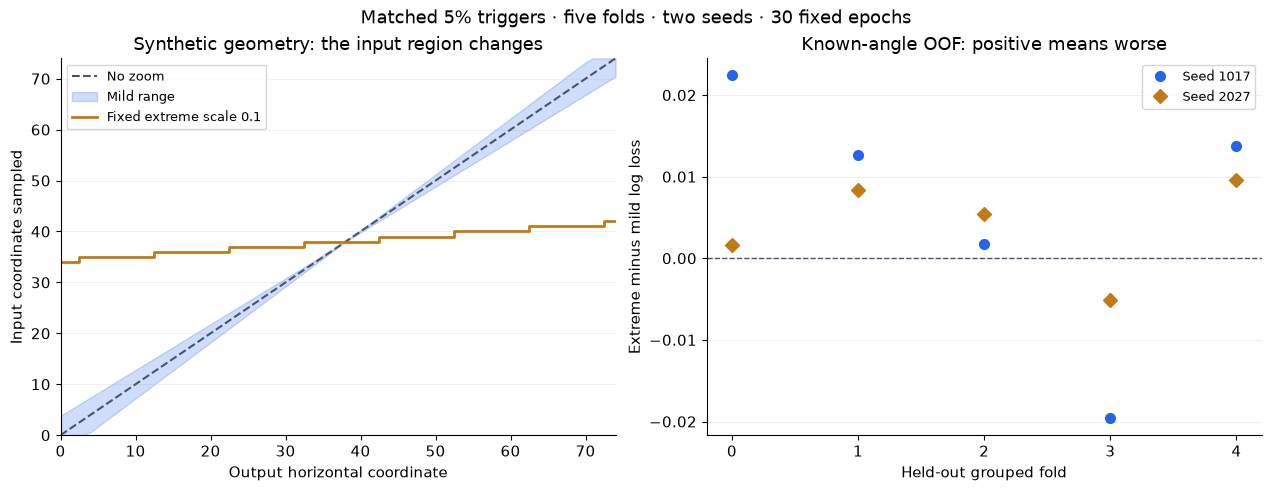

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(12.6, 4.8), constrained_layout=True)
coordinate = np.arange(75)
center = 38.0
axes[0].plot(coordinate, coordinate, color="#475569", linestyle="--", label="No zoom")
low = np.clip(center + 0.9 * (coordinate - center), 0, 74)
high = np.clip(center + 1.1 * (coordinate - center), 0, 74)
axes[0].fill_between(coordinate, np.minimum(low, high), np.maximum(low, high),
                     color="#2563EB", alpha=0.22, label="Mild range")
axes[0].step(coordinate, np.floor(center + 0.1 * (coordinate - center) + 0.5),
             where="mid", color="#C07A18", linewidth=2, label="Fixed extreme scale 0.1")
axes[0].set(xlabel="Output horizontal coordinate", ylabel="Input coordinate sampled",
            title="Synthetic geometry: the input region changes", xlim=(0, 74), ylim=(0, 74))
axes[0].legend(loc="upper left", fontsize=9)
paired = study["comparisons"]["extreme_5pct_minus_mild_5pct"]["known_angle_paired_fold_deltas"]
for seed, color, marker in [(1017, "#2563EB", "o"), (2027, "#C07A18", "D")]:
    rows = [row for row in paired if row["seed"] == seed]
    axes[1].plot([row["fold"] for row in rows], [row["delta"] for row in rows],
                 color=color, marker=marker, linestyle="none", markersize=7, label=f"Seed {seed}")
axes[1].axhline(0, color="#475569", linestyle="--", linewidth=1)
axes[1].set(xlabel="Held-out grouped fold", ylabel="Extreme minus mild log loss",
            title="Known-angle OOF: positive means worse", xticks=range(5))
axes[1].legend(loc="best", fontsize=9)
for ax in axes:
    ax.grid(axis="y", alpha=0.18)
fig.suptitle("Matched 5% triggers · five folds · two seeds · 30 fixed epochs", fontsize=13)
plt.show()


### Reconcile the reported delta and model reloads

In [4]:
comparison = study["comparisons"]["extreme_5pct_minus_mild_5pct"]
computed_delta = (results["Extreme, 5%"][0]
                  - results["Mild, 5%"][0])
assert abs(computed_delta - comparison["ensemble"]["known_angle"]) < 1e-12
assert study["default_equivalence"]["all_outputs_byte_identical"]
maximum_reload_delta = max(row["max_probability_delta"] for row in study["independent_reload_checks"])
assert maximum_reload_delta <= 1e-7
print({"rows": study["rows"], "known_angle_rows": study["known_angle_rows"],
       "models_independently_reloaded": 30, "maximum_reload_delta": maximum_reload_delta,
       "source": study["plan"]["source"]["git_commit"]})


{'rows': 1604, 'known_angle_rows': 1471, 'models_independently_reloaded': 30, 'maximum_reload_delta': 0.0, 'source': 'dd55e74364687cfa4e464208cab7db16ebb8930a'}


### Retain the shared exception and the opposite cohort effect

The exception is repeatable: **fold 3 improves in both seeds**, while the other four folds worsen in both. The result is therefore not driven by one unlucky seed, but it is not unanimous across acquisition-proxy folds either. It does not reveal which image or acquisition properties explain the exception.

The cohort direction also differs: extreme zoom lowers missing-angle loss from **0.029212 to 0.025324**, while increasing known-angle loss from **0.222293 to 0.226349**. The missing-angle cohort contains only 133 ships and is absent from test metadata; its improvement does not establish a test-relevant benefit. Keeping the known-angle endpoint primary avoids hiding that asymmetry in the pooled result.

No zoom has the lowest known-angle loss **among these three study arms**. That is not a direct comparison with the existing default, whose coupled affine scale was deliberately removed from every study arm.

## Takeaways

Extreme zoom has higher loss on the primary ensemble metric in this controlled setting. That does not establish a universally harmful transform or a defect in the historical model. Paired fold effects have mixed signs; retain that variation rather than treating the average as unanimous evidence.

Keep the normal default and recorded scores. A new default requires its own predeclared comparison and independent assessment, not selection on these reported outcomes. Original author intent remains unknown. No rows were removed, no thresholds/blend weights were retuned, and no leaderboard submission was made. [Full reasoning, source and limits](../docs/zoom-study.md).